# 02 - Feature engineering, model training & MLflow tracking
The training logic is in `src/heart/train.py`; this notebook runs it and looks at the results.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT / "src")); sys.path.insert(0, str(ROOT))
import warnings; warnings.filterwarnings("ignore")

## Preprocessing pipeline
* engineered feature `hr_pct_max` (achieved / age-predicted max heart rate)
* numeric -> median impute + StandardScaler
* binary -> most-frequent impute
* categorical (cp, restecg, slope, thal) -> most-frequent impute + One-Hot

All steps are inside one sklearn `Pipeline`, so the saved model contains the preprocessing too.

In [2]:
from heart.features import build_preprocessor
from heart.data import load_clean, split_xy
X, y = split_xy(load_clean())
pre = build_preprocessor().fit(X)
from heart.features import get_feature_names
import pandas as pd
pd.DataFrame(pre.transform(X.head()), columns=[n.split('__',1)[1] for n in pre.named_steps['columns'].get_feature_names_out()]).round(2)

,age,trestbps,chol,thalach,oldpeak,ca,hr_pct_max,sex,fbs,exang,...,cp_4,restecg_0,restecg_1,restecg_2,slope_1,slope_2,slope_3,thal_3,thal_6,thal_7
0,0.95,0.76,-0.26,0.02,1.09,-0.71,0.41,1.0,1.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0
1,1.39,1.61,0.76,-1.82,0.40,2.50,-1.54,1.0,0.0,1.0,...,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0
2,1.39,-0.67,-0.34,-0.90,1.35,1.43,-0.47,1.0,0.0,1.0,...,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0
3,-1.93,-0.10,0.06,1.64,2.12,-0.71,0.93,1.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0
4,-1.49,-0.10,-0.83,0.98,0.31,-0.71,0.45,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0


## Train + tune 3 models (logged to MLflow)
Training is run from the command line so it is reproducible and identical in CI:

```bash
PYTHONPATH=src python -m heart.train
```

Logistic Regression, Random Forest and Gradient Boosting are tuned with `GridSearchCV` (5-fold stratified CV, ROC-AUC). Every grid candidate is a nested MLflow run. Below the results are read back from the MLflow tracking store (`mlflow ui --backend-store-uri ./mlruns` shows the same data).

In [3]:
import mlflow
mlflow.set_tracking_uri((ROOT / 'mlruns').as_uri())
runs = mlflow.search_runs(experiment_names=['heart-disease-classifier'],
                          filter_string="tags.stage = 'tuning'", order_by=['start_time DESC'], max_results=3)
cols = ['metrics.cv_accuracy_mean','metrics.cv_precision_mean','metrics.cv_recall_mean',
        'metrics.cv_f1_mean','metrics.cv_roc_auc_mean','metrics.test_accuracy','metrics.test_roc_auc']
table = runs.set_index('tags.mlflow.runName')[cols]
table.columns = [c.replace('metrics.', '') for c in cols]
table.round(3)

,cv_accuracy_mean,cv_precision_mean,cv_recall_mean,cv_f1_mean,cv_roc_auc_mean,test_accuracy,test_roc_auc
tags.mlflow.runName,,,,,,,
gradient_boosting,0.818,0.827,0.774,0.796,0.874,0.902,0.959
random_forest,0.818,0.844,0.755,0.789,0.897,0.869,0.958
logistic_regression,0.851,0.887,0.783,0.828,0.907,0.869,0.960


In [4]:
# number of nested runs (grid candidates) per model family
all_runs = mlflow.search_runs(experiment_names=['heart-disease-classifier'])
print('total MLflow runs logged:', len(all_runs))
all_runs['tags.mlflow.runName'].str.replace(r'_cand\d+', '', regex=True).value_counts()

total MLflow runs logged: 66


tags.mlflow.runName
random_forest          26
logistic_regression    22
gradient_boosting      18
Name: count, dtype: int64

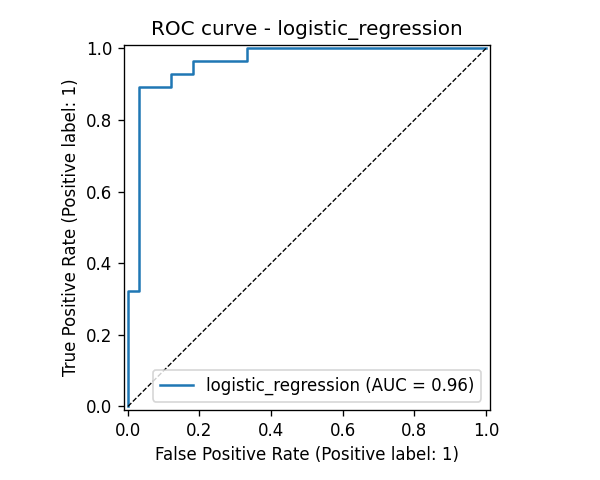

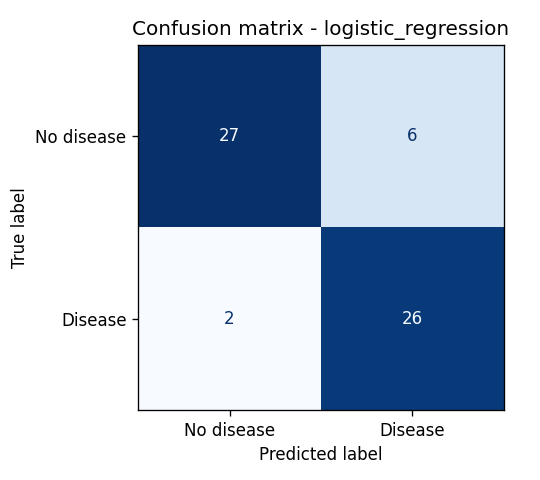

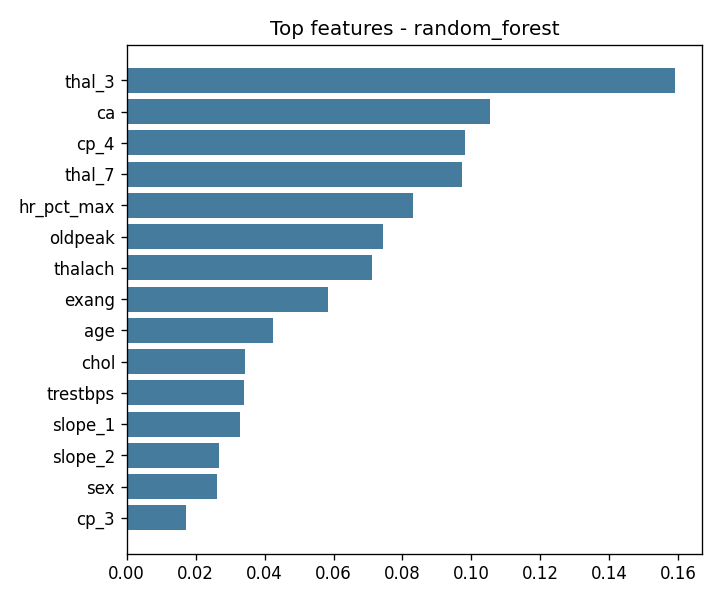

In [5]:
from IPython.display import Image, display
for name in ['roc_curve_logistic_regression', 'confusion_matrix_logistic_regression', 'feature_importance_random_forest']:
    display(Image(filename=str(ROOT / 'reports' / 'training' / f'{name}.png')))

## Model selection
The model with the highest **mean CV ROC-AUC** is exported (not the test score, to avoid picking a model using the test set). Logistic Regression wins: simple, well calibrated probabilities and easy to explain, which suits a small medical dataset.

In [6]:
import json
print(json.dumps(json.load(open(ROOT / 'models' / 'metadata.json')), indent=2))

{
  "model_name": "logistic_regression",
  "mlflow_run_id": "c800af5baf3243908af18500be38b5cc",
  "best_params": {
    "C": "0.5",
    "penalty": "l2"
  },
  "metrics": {
    "cv_accuracy_mean": 0.851,
    "cv_accuracy_std": 0.0285,
    "cv_f1_mean": 0.8277,
    "cv_f1_std": 0.032,
    "cv_precision_mean": 0.8873,
    "cv_precision_std": 0.0715,
    "cv_recall_mean": 0.783,
    "cv_recall_std": 0.0619,
    "cv_roc_auc_mean": 0.9075,
    "cv_roc_auc_std": 0.0201,
    "test_accuracy": 0.8689,
    "test_f1": 0.8667,
    "test_precision": 0.8125,
    "test_recall": 0.9286,
    "test_roc_auc": 0.96
  },
  "features": [
    "age",
    "trestbps",
    "chol",
    "thalach",
    "oldpeak",
    "ca",
    "sex",
    "fbs",
    "exang",
    "cp",
    "restecg",
    "slope",
    "thal"
  ],
  "trained_at": "2026-10-19T18:22:57+00:00"
}
